1. Paths and imports

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

NOTEBOOK_DIR = Path().resolve()
TASK_BASE = NOTEBOOK_DIR.parent

FEATURES_PATH = TASK_BASE / "data" / "features" / "csic_2010_features.csv"
TARGET_PATH = TASK_BASE / "data" / "features" / "csic_2010_target.csv"

X = pd.read_csv(FEATURES_PATH)
y_df = pd.read_csv(TARGET_PATH)

y = y_df["y"]

2. Drop constant features

In [5]:
# Drop constant features
# Drop zero-variance columns
constant_cols = [col for col in X.columns if X[col].nunique() == 1]
print("Dropping constant columns:", constant_cols)

X_clean = X.drop(columns=constant_cols)
print("Feature matrix after dropping constants:", X_clean.shape)

Dropping constant columns: ['has_content_length', 'has_content_type', 'cookie_length', 'url_question_count', 'url_ampersand_count', 'url_equals_count', 'url_percent_count', 'url_parameter_count', 'cookie_semicolon_count', 'cookie_equals_count', 'url_has_query', 'has_path_traversal']
Feature matrix after dropping constants: (61065, 36)


3. Train/test split (stratified)

In [7]:
# Using stratify=y ensures the 41% anomalous / 59% normal ratio is preserved in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,  # keeps class balance in both splits
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("Train class distribution:\n", pd.Series(y_train).value_counts().sort_index())
print("Test class distribution:\n", pd.Series(y_test).value_counts().sort_index())

Train size: 48852
Test size: 12213
Train class distribution:
 0    28800
1    20052
Name: y, dtype: int64
Test class distribution:
 0    7200
1    5013
Name: y, dtype: int64


4. Train logistic regression

In [9]:
# clf = LogisticRegression(
#     max_iter=1000,  # allow more iterations to converge
#     random_state=42,
# )

# clf.fit(X_train, y_train)
# print("Logistic regression trained.")
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",  # or "saga"
        random_state=42,
    )),
])

clf.fit(X_train, y_train)
print("Logistic regression trained with scaling.")

Logistic regression trained with scaling.


5. Evaluate on test set

In [10]:
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1:        {f1:.4f}")

print("\nClassification report:\n")
print(classification_report(y_test, y_pred, digits=4))

Accuracy:  0.7655
Precision: 0.7692
Recall:    0.6124
F1:        0.6819

Classification report:

              precision    recall  f1-score   support

           0     0.7637    0.8721    0.8143      7200
           1     0.7692    0.6124    0.6819      5013

    accuracy                         0.7655     12213
   macro avg     0.7665    0.7422    0.7481     12213
weighted avg     0.7660    0.7655    0.7600     12213



In [ ]:
6. Confusion matrix

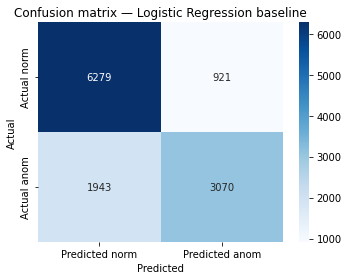

TN: 6279, FP: 921, FN: 1943, TP: 3070


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted norm", "Predicted anom"],
    yticklabels=["Actual norm", "Actual anom"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — Logistic Regression baseline")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

7. Inspect top features

In [12]:
feature_names = X_clean.columns
coefs = pd.Series(clf.coef_[0], index=feature_names).sort_values(ascending=False)

print("Top 10 positive coefficients (push toward anom):")
print(coefs.head(10))

print("\nTop 10 negative coefficients (push toward norm):")
print(coefs.tail(10))

AttributeError: 'Pipeline' object has no attribute 'coef_'